# The relational bottleneck solves XOR
A standard self-attention head computes its values from the input, $V = XW_v$. A **relational attention head** instead uses a learned value matrix $V$ that does *not* depend on the input:

$$
\text{SelfAttention}(X) = \sigma\!\left(\tfrac{XW_q (XW_k)^\top}{\sqrt{d}}\right) XW_v
\qquad
\text{RelationalAttention}(X) = \sigma\!\left(\tfrac{XW_q (XW_k)^\top}{\sqrt{d}}\right) V
$$

where $\sigma$ is a row-wise softmax (or the identity, for the *linear* variants). Because $V$ is fixed, the only thing that can reach the classifier is the attention pattern, i.e. *how the tokens relate to each other*, not what the tokens are. This is the relational bottleneck.

This notebook trains both heads on XOR: two one-hot tokens in $\mathbb{R}^2$, labelled 1 if they differ.

## Imports

In [1]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

from relational_attention.tasks import XORDataset
from relational_attention.models import SelfAttentionHead, RelationalAttentionHead, AttentionClassifier
from relational_attention.training import train_model, evaluate_model

In [2]:
torch.manual_seed(0)

## The task

In [3]:
# Parameters
num_samples = 1000
num_vectors = 2
vector_len = 2

In [4]:
dataset = XORDataset(num_samples=num_samples, num_vectors=num_vectors, vector_len=vector_len)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

In [5]:
# The four distinct inputs and their labels
inputs, idx = np.unique(dataset.data.flatten(start_dim=1).numpy(), axis=0, return_index=True)
for x, i in zip(inputs, idx):
    print(x.reshape(num_vectors, vector_len).tolist(), '->', int(dataset.labels[i]))

[[0.0, 1.0], [0.0, 1.0]] -> 0
[[0.0, 1.0], [1.0, 0.0]] -> 1
[[1.0, 0.0], [0.0, 1.0]] -> 1
[[1.0, 0.0], [1.0, 0.0]] -> 0


## Train the four attention heads

In [6]:
lr = 1e-3
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 250

In [7]:
variants = {
    'Self attention': (SelfAttentionHead, False),
    'Relational attention': (RelationalAttentionHead, False),
    'Linear self attention': (SelfAttentionHead, True),
    'Linear relational attention': (RelationalAttentionHead, True),
}

models, losses = {}, {}
for name, (attn_cls, linear) in variants.items():
    torch.manual_seed(0)
    models[name] = AttentionClassifier(
        embed_dim=vector_len, head_dim=vector_len, context_size=num_vectors, attn_cls=attn_cls, linear=linear
    )
    optimizer = torch.optim.Adam(models[name].parameters(), lr=lr)
    losses[name] = train_model(models[name], loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs, verbose=False)
    print(f'{name:28s} final loss {losses[name][-1]:.4f}   accuracy {evaluate_model(models[name], loader):.3f}')

Self attention               final loss 0.4840   accuracy 0.744


Relational attention         final loss 0.0000   accuracy 1.000


Linear self attention        final loss 0.0000   accuracy 1.000


Linear relational attention  final loss 0.0000   accuracy 1.000


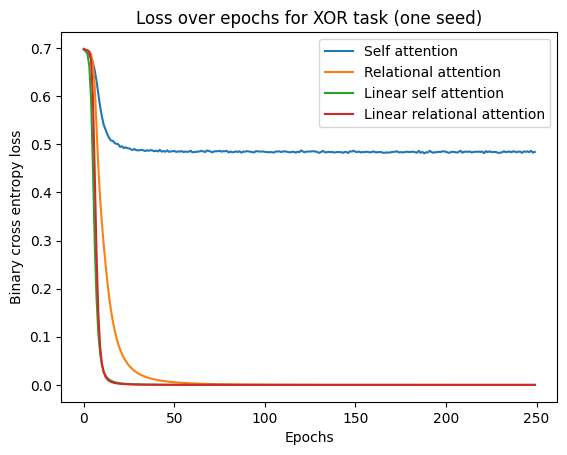

In [8]:
for name, loss in losses.items():
    plt.plot(loss, label=name)

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for XOR task (one seed)')
plt.legend()
plt.show()

## How the relational head solves it
Softmax self-attention gets stuck, while all three other heads solve the task. Removing the softmax is enough to fix self-attention here, so the relational bottleneck is one of two fixes rather than the only one.

Because the relational head's values are fixed, it can only signal the label through its attention pattern. Below are the attention weights the softmax relational head assigns for each of the four inputs: for *same* inputs both tokens attend uniformly, and for *different* inputs each token attends entirely to the other token. The fixed value slots turn these two patterns into linearly separable outputs.

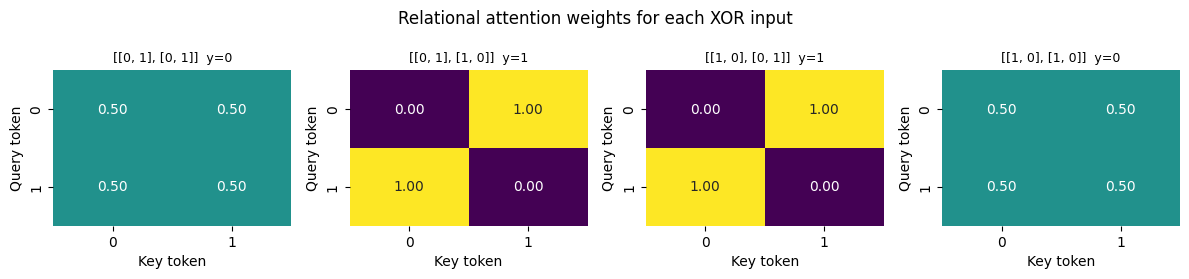

In [9]:
model = models['Relational attention']
model.eval()

fig, axes = plt.subplots(1, len(inputs), figsize=(3 * len(inputs), 2.8))
with torch.no_grad():
    for ax, x, i in zip(axes, inputs, idx):
        X = torch.tensor(x, dtype=torch.float32).reshape(1, num_vectors, vector_len)
        _, attn = model.attn(X)
        sns.heatmap(attn[0], vmin=0, vmax=1, cmap='viridis', annot=True, fmt='.2f', cbar=False, ax=ax)
        ax.set_title(f'{x.reshape(num_vectors, vector_len).astype(int).tolist()}  y={int(dataset.labels[i])}', fontsize=9)
        ax.set_xlabel('Key token')
        ax.set_ylabel('Query token')

plt.suptitle('Relational attention weights for each XOR input')
plt.tight_layout()
plt.show()

## Across 30 seeds
`scripts/xor_batch.py` trains each head from 30 random initializations (run it from the repo root). Shaded regions are $\pm 1$ standard deviation.

In [10]:
results = pd.read_csv('../data/xor_results.csv')
results.head()

,seed,epoch,self_attention_loss,relational_attention_loss,self_attention_linear_loss,relational_attention_linear_loss
0,0,0,0.696811,0.697639,0.697843,0.697983
1,0,1,0.693042,0.695871,0.694690,0.696248
2,0,2,0.689551,0.694433,0.687081,0.695296
3,0,3,0.685653,0.692258,0.663255,0.692468
4,0,4,0.679335,0.686873,0.594158,0.674315


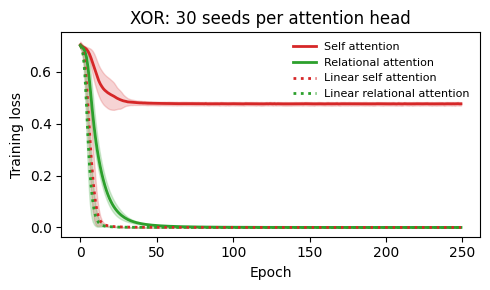

In [11]:
labels = {
    'self_attention_loss': ('Self attention', 'tab:red', '-'),
    'relational_attention_loss': ('Relational attention', 'tab:green', '-'),
    'self_attention_linear_loss': ('Linear self attention', 'tab:red', ':'),
    'relational_attention_linear_loss': ('Linear relational attention', 'tab:green', ':'),
}
stats = results.groupby('epoch').agg(['mean', 'std'])
epochs_axis = stats.index.values

fig, ax = plt.subplots(figsize=(5, 3))
for column, (label, color, style) in labels.items():
    mean, std = stats[column]['mean'], stats[column]['std']
    ax.plot(epochs_axis, mean, label=label, linewidth=2, color=color, linestyle=style)
    ax.fill_between(epochs_axis, mean - std, mean + std, alpha=0.2, color=color)

ax.set_xlabel('Epoch')
ax.set_ylabel('Training loss')
ax.set_title('XOR: 30 seeds per attention head')
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig('../results/xor_training_dynamics.svg', bbox_inches='tight')
plt.show()

In [12]:
final = results[results.epoch == results.epoch.max()]
summary = pd.DataFrame({
    'mean final loss': final[list(labels)].mean(),
    'seeds with loss < 0.05': (final[list(labels)] < 0.05).sum(),
})
summary.index = [labels[c][0] for c in summary.index]
summary

,mean final loss,seeds with loss < 0.05
Self attention,4.771173e-01,0
Relational attention,2.966835e-06,30
Linear self attention,7.530345e-08,30
Linear relational attention,3.723729e-08,30
